# TP3 : clustering

In [1]:
import collections
import os
import string

# pour le nuage de mot
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

# pour le clustering
import pandas as pd
from nltk import word_tokenize
from nltk.corpus import stopwords
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
#import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine

import nltk

nltk.download('punkt')
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tvh\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\tvh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\tvh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [2]:
data_path = "../../data/txt/"

# choix de la décennie
DECADE = '1930'

# charger tous les fichiers de la décennie et en créer une liste de texte
files = [f for f in sorted(os.listdir(data_path)) if f"_{DECADE[:-1]}" in f]
texts = [open(data_path + f, "r", encoding="utf-8").read() for f in files]

# mettre texts dans un fichier ?

# blablabla Vectoriser les documents à l'aide de TF-IDF

In [3]:
# Création d'une fonction de pré-traitement
def preprocessing(text, stem=True):
    """ Tokenize text and remove punctuation """
    text = text.translate(string.punctuation)
    tokens = word_tokenize(text)
    return tokens

In [4]:
vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

In [5]:
### Construire la matrice de vecteurs à l'aide de la fonction `fit_transform`
tfidf_vectors = vectorizer.fit_transform(texts)

# Détail de la matrice
tfidf_vectors

### Imprimer le vecteur tf-IDF du premier document
pd.Series(
    tfidf_vectors[0].toarray()[0],
    index=vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

c:\Users\tvh\Documents\ULB\6 - ma2\tac\from git\tac2026\.venv\Lib\site-packages\sklearn\feature_extraction\text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


id                0.454642
janvier           0.243595
disp              0.217604
no                0.190022
ld                0.180150
                    ...   
étages            0.000000
étage             0.000000
établissements    0.000000
établissement     0.000000
-a                0.000000
Length: 3938, dtype: float64

## Appliquer un algorithme de clustering sur les vecteurs TF-IDF des documents

In [6]:
# nombre de cluster
N_CLUSTERS = 7

# instancier k-means et ses arguments
km_model = KMeans(n_clusters=N_CLUSTERS)

# appliquer le clustering à l'aide de la fonction fit_predict
clusters = km_model.fit_predict(tfidf_vectors)

clustering = collections.defaultdict(list)

In [7]:
for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

pprint(dict(clustering))

{np.int32(0): ['KB_JB838_1930-01-24_01-00008.txt',
               'KB_JB838_1930-04-07_01-00009.txt',
               'KB_JB838_1930-05-06_01-00008.txt',
               'KB_JB838_1930-05-08_01-00008.txt',
               'KB_JB838_1930-05-28_01-00009.txt',
               'KB_JB838_1930-06-20_01-00008.txt',
               'KB_JB838_1930-08-27_01-00007.txt',
               'KB_JB838_1930-09-21_01-00011.txt',
               'KB_JB838_1930-10-14_01-00009.txt',
               'KB_JB838_1930-10-26_01-00011.txt',
               'KB_JB838_1930-11-03_01-00007.txt',
               'KB_JB838_1930-11-10_01-00007.txt',
               'KB_JB838_1930-11-21_01-00008.txt',
               'KB_JB838_1930-12-23_01-00012.txt',
               'KB_JB838_1931-01-09_01-00008.txt',
               'KB_JB838_1931-02-21_01-00008.txt',
               'KB_JB838_1931-03-10_01-00009.txt',
               'KB_JB838_1931-03-24_01-00008.txt',
               'KB_JB838_1931-04-19_01-00013.txt',
               'KB_JB838_1931-0

# visualiser les clusters
### Réduire les vecteurs à 2 dimensions à l'aide de l'algorithme PCA
Cette étape est nécessaire afin de visualiser les documents dans un espace 2D

https://fr.wikipedia.org/wiki/Analyse_en_composantes_principales

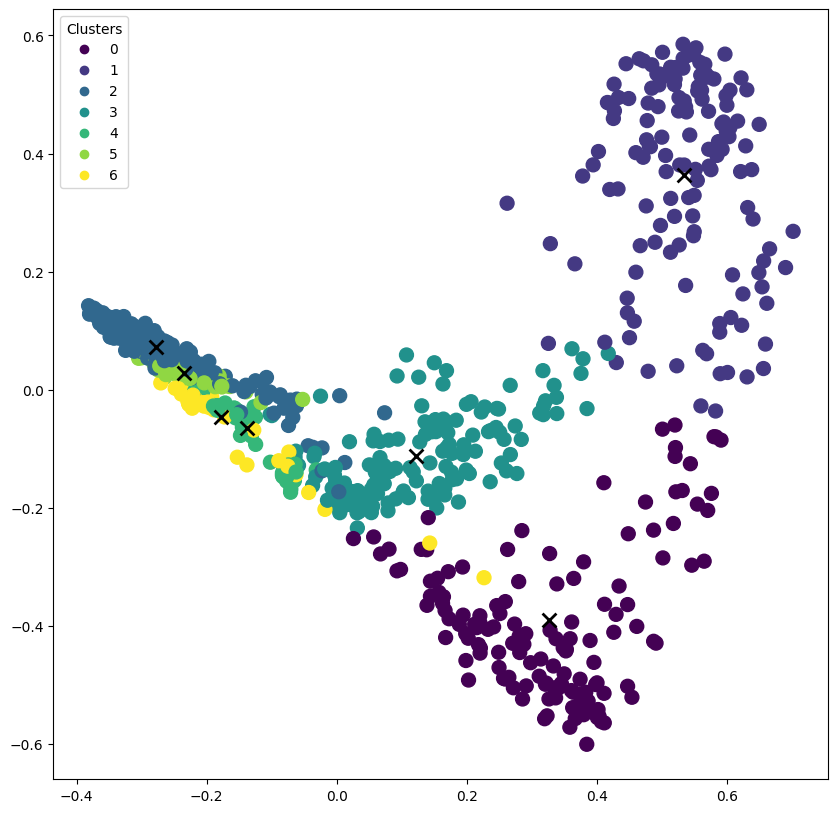

In [8]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

reduced_vectors[:10]

x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10,10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

# Ajouter les centroïdes
centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],  marker = "x", s=100, linewidths = 2, color='black')

# Ajouter la légende
plt.legend(handles=scatter.legend_elements()[0], labels=set(clusters), title="Clusters")

# corpus par cluster

In [9]:
output_path = '../../data/TP3/'
cluster_dico = dict(clustering)
#texts = [open(data_path + f, "r", encoding="utf-8").read() for f in cluster_dico[i]]

for i in range(N_CLUSTERS):
    #texts = [open(data_path + f, "r", encoding="utf-8").read() for f in cluster_dico[i]]
    texts = ""
    for f in cluster_dico[i]:
        texts += open(data_path + f, "r", encoding="utf-8").read()

    new_file_path = f"{output_path}/corpus_cluster_{i}.txt"
    output = open(new_file_path, "w", encoding='utf-8')
    output.write(texts)

# nuage de mot par cluster

In [10]:
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
sw = set(sw)

In [14]:
def clean_text(i, folder=None):
    if folder is None:
        input_path = f"corpus_cluster_{i}.txt"
        output_path = f"corpus_cluster_{i}_clean.txt"
    else:
        input_path = f"{folder}corpus_cluster_{i}.txt"
        output_path = f"{folder}corpus_cluster_{i}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [15]:
for i in range(N_CLUSTERS):
    clean_text(i, output_path)

In [17]:
def word_cloud(i):
    corpus_cluster_path = "../../data/TP3"

    with open(os.path.join(corpus_cluster_path, f'corpus_cluster_{i}_clean.txt'), 'r', encoding='utf-8') as f:
        after = f.read()

    frequencies = Counter(after.split())
    #print(frequencies.most_common(10))

    cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
    cloud.to_file(os.path.join(corpus_cluster_path, f"wc_cluster_{i}.png"))
    Image(filename=os.path.join(corpus_cluster_path, f"wc_cluster_{i}.png"))

In [18]:
for i in range(N_CLUSTERS):
    word_cloud(i)